04 - Embeat Recommendation Model Evaluation
1. Mục tiêu
Đánh giá năm phương pháp đề xuất trên cùng tập truy vấn:
1. Audio-only
2. Hybrid 70/30
3. Hybrid + MMR
4. Random Baseline
5. Popularity Baseline
2. Chỉ số
- Mean Audio Cosine: tương đồng âm học trung bình (cao hơn nghĩa là gần hơn về âm học)
- Mean Acoustic Distance: 1 - cosine (thấp hơn nghĩa là gần hơn về âm học)
- Audio Diversity: 1 - mean pairwise audio cosine trong danh sách gợi ý
- Coverage (%): tỷ lệ bài hát khác nhau được đề xuất trên tổng catalog
- Mean Latency (ms): thời gian phản hồi trung bình
3. Cấu hình
- Dataset: Embeat Spotify Tracks; model artifact thực nghiệm 29.985 tracks
- Queries: 30; Top-N: 10; Alpha: 0.7; MMR Lambda: 0.7
- Candidate Pool: 50; Random State: 42
Giới hạn: Không có nhãn relevance ground truth; không báo cáo Accuracy, Precision@K hoặc Recall@K. Độ tương đồng âm học không phải độ chính xác theo sở thích người dùng.

In [1]:
from pathlib import Path
import sys
import json
import importlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/content/drive/MyDrive/music_recommender_project")
assert (PROJECT_ROOT / "src" / "evaluate.py").exists(), "Missing src/evaluate.py"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.evaluate as evaluation
importlib.reload(evaluation)

ARTIFACT_PATH = PROJECT_ROOT / "artifacts" / "embeat_recommender.joblib"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

evaluation.ARTIFACT_PATH = ARTIFACT_PATH
evaluation.OUTPUT_DIR = REPORTS_DIR

print("Project root:", PROJECT_ROOT)
print("Artifact:", ARTIFACT_PATH)
print("Reports directory:", REPORTS_DIR)
assert ARTIFACT_PATH.exists(), "Main model artifact not found"


Project root: /content/drive/MyDrive/music_recommender_project
Artifact: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_recommender.joblib
Reports directory: /content/drive/MyDrive/music_recommender_project/reports


In [2]:
print("=== EVALUATION CONFIGURATION ===")

print("Top N:", evaluation.TOP_N)
print("Number of queries:", evaluation.N_QUERIES)
print("Alpha:", evaluation.ALPHA)
print("MMR Lambda:", evaluation.MMR_LAMBDA)
print("Candidate Pool:", evaluation.CANDIDATE_POOL)
print("Random State:", evaluation.RANDOM_STATE)

print("\nArtifact exists:", ARTIFACT_PATH.exists())
print("Reports directory exists:", REPORTS_DIR.exists())

=== EVALUATION CONFIGURATION ===
Top N: 10
Number of queries: 30
Alpha: 0.7
MMR Lambda: 0.7
Candidate Pool: 50
Random State: 42

Artifact exists: True
Reports directory exists: True


In [3]:
evaluation.main()

Loaded: 29985 tracks; audio: (29985, 9) ; genres: (29985, 4211)
Evaluating: Audio-only
Evaluating: Hybrid 70/30
Evaluating: Hybrid + MMR
Evaluating: Random Baseline
Evaluating: Popularity Baseline
Dashboard: /content/drive/MyDrive/music_recommender_project/reports/evaluation_dashboard.png
              model  mean_audio_cosine  mean_acoustic_distance  audio_diversity  coverage_pct  mean_latency_ms
         Audio-only           0.960541                0.039459         0.064865      1.000500         6.862716
       Hybrid 70/30           0.929475                0.070525         0.096500      1.000500        10.659640
       Hybrid + MMR           0.936586                0.063414         0.111791      0.997165        13.398468
    Random Baseline           0.013582                0.986418         0.986175      0.997165         3.978803
Popularity Baseline           0.027189                0.972811         0.741555      0.033350        11.211401
EVALUATION COMPLETED SUCCESSFULLY


In [4]:
metrics_path = REPORTS_DIR / "metrics.json"
summary_path = REPORTS_DIR / "evaluation_summary.csv"
details_path = REPORTS_DIR / "evaluation_details.csv"

assert metrics_path.exists()
assert summary_path.exists()
assert details_path.exists()

with open(metrics_path, "r", encoding="utf-8") as f:
    metrics = json.load(f)

summary_df = pd.read_csv(summary_path)
details_df = pd.read_csv(details_path)

print("=== EVALUATION CONFIG ===")
print(json.dumps(
    metrics["evaluation_config"],
    indent=4,
    ensure_ascii=False
))

print("\n=== EVALUATION SUMMARY ===")
display(summary_df)

print("\n=== EVALUATION DETAILS ===")
display(details_df.head(10))

=== EVALUATION CONFIG ===
{
    "n_queries": 30,
    "top_n": 10,
    "alpha": 0.7,
    "mmr_lambda": 0.7,
    "candidate_pool": 50,
    "random_state": 42
}

=== EVALUATION SUMMARY ===


,model,total_queries,total_recommendations,unique_recommended_tracks,avg_unique_artists,avg_unique_genres,avg_popularity,mean_latency_ms,median_latency_ms,std_latency_ms,...,mean_audio_cosine,mean_acoustic_distance,mean_hybrid_cosine,audio_diversity,hybrid_diversity,avg_similarity,intra_list_diversity,catalog_size,coverage_pct,avg_mmr_score
0,Audio-only,30,300,300,9.700000,12.400000,0.266100,6.862716,5.958059,4.096306,...,0.960541,0.039459,0.682358,0.064865,0.337191,0.960541,0.064865,29985,1.000500,NaN
1,Hybrid 70/30,30,300,300,9.000000,11.200000,0.309800,10.659640,10.499480,0.491399,...,0.929475,0.070525,0.720761,0.096500,0.303106,0.929475,0.096500,29985,1.000500,NaN
2,Hybrid + MMR,30,300,299,9.433333,11.966667,0.260400,13.398468,12.888636,1.566901,...,0.936586,0.063414,0.714932,0.111791,0.336725,0.936586,0.111791,29985,0.997165,0.312302
3,Random Baseline,30,300,299,10.000000,14.133333,0.268433,3.978803,3.887938,0.251561,...,0.013582,0.986418,0.011200,0.986175,0.989832,0.013582,0.986175,29985,0.997165,NaN
4,Popularity Baseline,30,300,10,10.000000,30.000000,0.820000,11.211401,10.487008,1.989710,...,0.027189,0.972811,0.021856,0.741555,0.812168,0.027189,0.741555,29985,0.033350,NaN



=== EVALUATION DETAILS ===


,model,query_id,rank,track_id,track_name,artist_name,artist_genres,popularity,mean_audio_cosine,mean_acoustic_distance,mean_hybrid_cosine,audio_diversity,hybrid_diversity,similarity,audio_similarity,genre_similarity,hybrid_similarity,mmr_score
0,Audio-only,20VBgkEWUKqnTa677QQPX0,1,3gky07d1PehSRTQ1GIRJBZ,JOY COMES FROM THE LORD,KS,NaN,0.02,0.87581,0.12419,0.613067,0.203169,0.442218,0.909667,NaN,NaN,NaN,NaN
1,Audio-only,20VBgkEWUKqnTa677QQPX0,2,20VUAbNMl2JaWD5Ti2LUAp,Bitte hört auf,JACE,"german alternative rap, german cloud rap",0.07,0.87581,0.12419,0.613067,0.203169,0.442218,0.892511,NaN,NaN,NaN,NaN
2,Audio-only,20VBgkEWUKqnTa677QQPX0,3,4aOOExMBUyxKnEYb39SrTg,Riot,XXXTENTACION,"miami hip hop, emo rap",0.73,0.87581,0.12419,0.613067,0.203169,0.442218,0.885413,NaN,NaN,NaN,NaN
3,Audio-only,20VBgkEWUKqnTa677QQPX0,4,3gbkvfmlNd4r8MaDyuwTIv,Control dis .40,Damnnnsolo,NaN,0.02,0.87581,0.12419,0.613067,0.203169,0.442218,0.884798,NaN,NaN,NaN,NaN
4,Audio-only,20VBgkEWUKqnTa677QQPX0,5,7eRJjg52FkSmQvmNQDYpMl,worst behaviour (feat. Kehlani),Kehlani,"r&b, pop, rap",0.76,0.87581,0.12419,0.613067,0.203169,0.442218,0.867802,NaN,NaN,NaN,NaN
5,Audio-only,20VBgkEWUKqnTa677QQPX0,6,3hLAKLijSDedibJSB1BwxT,bbo,lordkez,south african r&b,0.02,0.87581,0.12419,0.613067,0.203169,0.442218,0.866568,NaN,NaN,NaN,NaN
6,Audio-only,20VBgkEWUKqnTa677QQPX0,7,1yYg5wpCJybzFUeD0TUDlK,Solid Foundation,Illuminati Congo,"spiritual hip hop, high vibe",0.07,0.87581,0.12419,0.613067,0.203169,0.442218,0.865779,NaN,NaN,NaN,NaN
7,Audio-only,20VBgkEWUKqnTa677QQPX0,8,1Mzg6bu3hkCwJKEf7v49MN,CARTIER SANTOS,SDM,"pop urbaine, french hip hop, r&b francais",0.77,0.87581,0.12419,0.613067,0.203169,0.442218,0.864659,NaN,NaN,NaN,NaN
8,Audio-only,20VBgkEWUKqnTa677QQPX0,9,3h2fb1JsD4FK1FPkAJjwyW,Powiedz co czujesz,KD Producent,NaN,0.02,0.87581,0.12419,0.613067,0.203169,0.442218,0.860511,NaN,NaN,NaN,NaN
9,Audio-only,20VBgkEWUKqnTa677QQPX0,10,20WujVDIQfXZDy2g3pzIGM,Ezekiel 33,Streetlights,bible,0.07,0.87581,0.12419,0.613067,0.203169,0.442218,0.860394,NaN,NaN,NaN,NaN


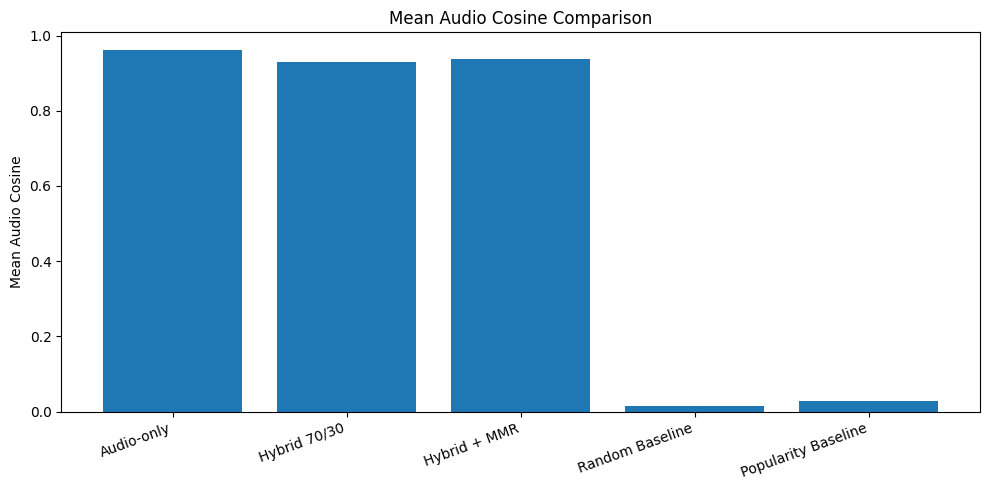

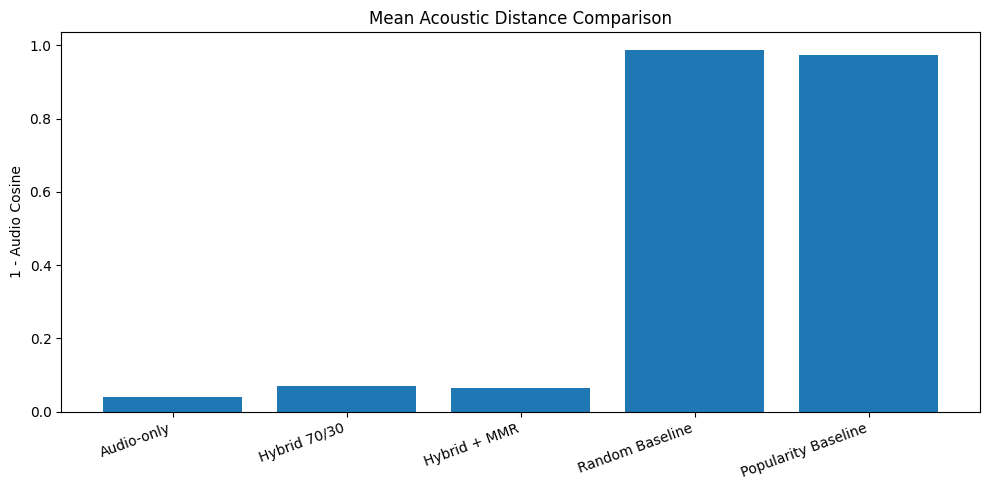

In [5]:
required_metrics = ["model", "mean_audio_cosine", "mean_acoustic_distance", "audio_diversity", "coverage_pct", "mean_latency_ms"]
missing = [col for col in required_metrics if col not in summary_df.columns]
assert not missing, f"Missing evaluation columns: {missing}. Check src/evaluate.py version."

plt.figure(figsize=(10, 5))
plt.bar(summary_df["model"], summary_df["mean_audio_cosine"])
plt.title("Mean Audio Cosine Comparison")
plt.ylabel("Mean Audio Cosine")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(summary_df["model"], summary_df["mean_acoustic_distance"])
plt.title("Mean Acoustic Distance Comparison")
plt.ylabel("1 - Audio Cosine")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


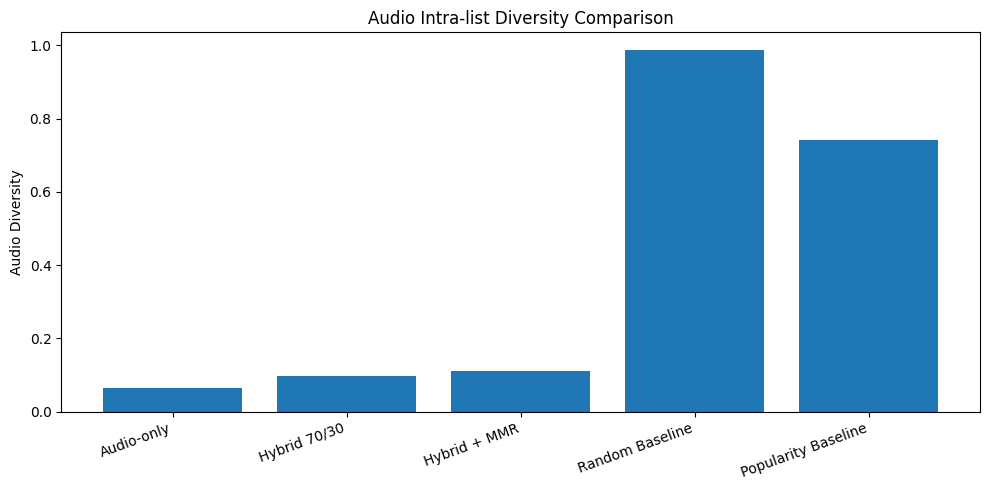

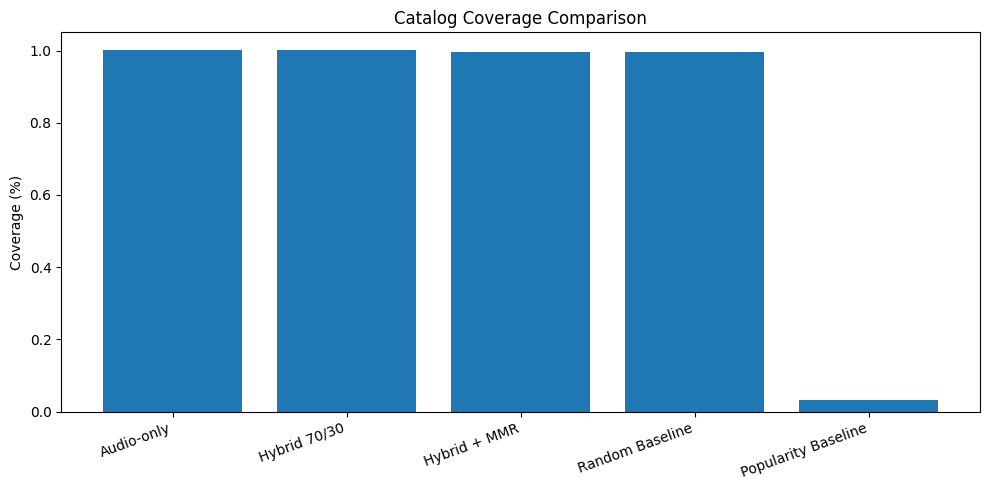

In [6]:
plt.figure(figsize=(10, 5))
plt.bar(summary_df["model"], summary_df["audio_diversity"])
plt.title("Audio Intra-list Diversity Comparison")
plt.ylabel("Audio Diversity")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(summary_df["model"], summary_df["coverage_pct"])
plt.title("Catalog Coverage Comparison")
plt.ylabel("Coverage (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


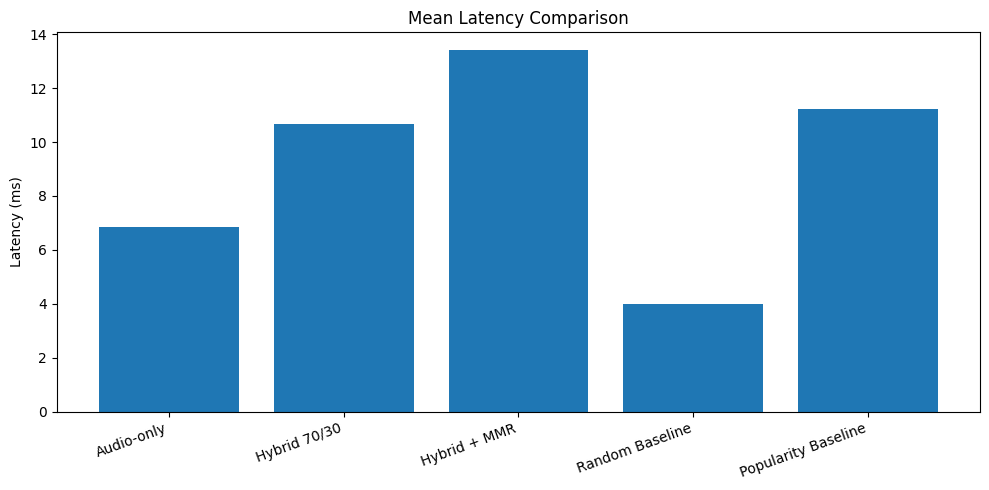

In [7]:
plt.figure(figsize=(10, 5))
plt.bar(summary_df["model"], summary_df["mean_latency_ms"])
plt.title("Mean Latency Comparison")
plt.ylabel("Latency (ms)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


In [8]:
print("=== EVALUATION VALIDATION ===")
expected_models = {
    "Audio-only", "Hybrid 70/30", "Hybrid + MMR",
    "Random Baseline", "Popularity Baseline"
}
assert len(summary_df) == 5, f"Expected 5 methods, got {len(summary_df)}"
assert set(summary_df["model"]) == expected_models
assert len(details_df) > 0
assert metrics["catalog_size"] == 29985
assert metrics["evaluation_config"]["n_queries"] == 30
assert summary_df[required_metrics[1:]].notna().all().all()

print("Number of evaluated methods:", len(summary_df))
print("Number of queries:", metrics["evaluation_config"]["n_queries"])
print("Number of recommendations:", len(details_df))
print("Generated files:")
for path in [metrics_path, summary_path, details_path, REPORTS_DIR / "evaluation_dashboard.png"]:
    assert path.exists(), f"Missing output: {path}"
    print(path.name, "-", round(path.stat().st_size / 1024, 2), "KB")
print("EVALUATION NOTEBOOK VALIDATION: PASS")


=== EVALUATION VALIDATION ===
Number of evaluated methods: 5
Number of queries: 30
Number of recommendations: 1500
Generated files:
metrics.json - 7.07 KB
evaluation_summary.csv - 1.93 KB
evaluation_details.csv - 393.62 KB
evaluation_dashboard.png - 327.43 KB
EVALUATION NOTEBOOK VALIDATION: PASS
